# El experimento ganador, partiendo del deposito real

Este notebook junta en un solo lugar la mejor configuracion encontrada con el regimen de simulacion del
proyecto, con todos sus modelos y parametros a la vista, para leerlo sin los notebooks anteriores.

**Pregunta.** Partiendo del deposito como esta, cuanto baja la caminata de los pickers con un slotting
que incorpora la afinidad de los datos, implementado de a poco, y de que depende esa ganancia.

**La configuracion ganadora** (por que es esta, en la seccion 9):
- slotting `merchant_aisle_fill`: cada merchant en un pasillo;
- el plan entra solo por las mudanzas de las reposiciones, con la regla `plan_aisle` (cuando un SKU se
  agota, va a su pasillo del plan);
- los batches se re-arman por pasillo con ventana $W = 4$, con el pasillo que cada SKU tiene en ese
  momento.

Todo se compara con **hoy**: el deposito real, con reposiciones como en los datos y batches FIFO.

**Contenido.**
0. Configuracion: todos los parametros.
1. Datos y particion.
2. La afinidad que tienen los datos.
3. El recorrido en S.
4. El slotting ganador.
5. Como entra el plan: la regla.
6. Como se arman los batches y cuanto espera una orden.
7. Resultados en `medium`.
8. Otros depositos.
9. Por que esta configuracion: lo que dijo la grilla.
10. Lectura.

## 0. Configuracion

| componente | parametro | valor | que hace |
|---|---|---|---|
| datos | deposito | `medium`; la seccion 8 repite con `small`, `medium-alpha-1.3` y `big` | carpeta de `data/v2` |
| particion | fraccion de test | 0,4 | los batches se ordenan por la hora de su primera linea; el ultimo 40% es test, 72 dias (unas 10 semanas) |
| instancia | demanda $f_i$ | `pick_lines` | fraccion de las lineas de train que piden el SKU $i$ |
| instancia | costo $c_l$ | distancia caminando de la bay de la ubicacion $l$ al dock | ordena las ubicaciones |
| instancia | afinidad $a_{ij}$ | `jaccard` sobre las ordenes de train, 10 vecinos por SKU, normalizada | solo para medir la afinidad (seccion 2); el ganador no la usa |
| ruteo | recorrido | `s_shape` | S estricto (seccion 3) |
| slotting | metodo | `merchant_aisle_fill` | regla de la seccion 4; sin parametros |
| simulacion | estado inicial | el deposito real al corte | nada se mueve de antemano |
| simulacion | reposicion | `plan_aisle`, `trigger="stockout"`, `target="aisle"` | seccion 5 |
| batching | ordenes por batch, ventana, pasadas | 25; $W = 4$; 20 | seccion 6 |
| referencia | hoy | deposito real, reposicion `random` (como en los datos), FIFO | todas las diferencias son contra hoy |
| referencia | techo | el plan aplicado de una vez, reposicion `home` | lo que daria el plan con el deposito reordenado el primer dia |
| medidas | promedio y final | caminata media por batch en todo el test y en los ultimos 14 dias | el final muestra hasta donde se llega |

In [1]:
import gc
import inspect
import time
from collections import Counter
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from abs_affinity_based_slotting.config import PROJECT_ROOT, dataset_dir
from abs_affinity_based_slotting.data import WarehouseDataLoader, split_picking_events
from abs_affinity_based_slotting.demand import TopKFilter
from abs_affinity_based_slotting.slotting import build_full_instance, Assignment
from abs_affinity_based_slotting.methods import method_registry
from abs_affinity_based_slotting.methods import aisle_fill as modulo_aisle_fill
from abs_affinity_based_slotting.simulation import (Simulator, split_replenishments, build_event_stream,
                                                    state_from_initial_stock, state_after_history, reslot_state,
                                                    HomePolicy, RandomStoragePolicy, PlanAislePolicy,
                                                    simulate_rolling, location_aisles)
from abs_affinity_based_slotting.simulation import plan_aisle as modulo_plan_aisle
from abs_affinity_based_slotting.batching import AisleCoverBatching, orders_by_arrival, order_waits
from abs_affinity_based_slotting.experiments import load_results

pd.set_option("display.width", 180)

# ---- configuracion (tabla de arriba)
DATASET = "medium"
OTROS = ["small", "medium-alpha-1.3"]
TEST_SIZE = 0.4
INSTANCIA = dict(demand_metric="pick_lines", affinity_metric="jaccard", cooccurrence_col="order_id",
                 affinity_filter=TopKFilter(k=10), normalize=True, pair_distance_model="aisle")
BATCH_SIZE = 25
VENTANA = 4
VENTANAS = [1, 2, 4, 8, 16]
MAX_PASSES = 20
SEMILLA = 0
GANADOR = "merchant_aisle_fill"
GRILLA = PROJECT_ROOT / "results" / "correct_base_02_combinatoria"   # resultados de 02_combinatoria

## 1. Datos y particion

Los datos son un deposito sintetico que genero ShipHero: seis meses de lineas de picking con la orden y
el batch de cada una, el stock inicial, las reposiciones y el plano. `split_picking_events` deja el
ultimo 40% de los batches como test; `build_full_instance` arma la instancia con train;
`state_after_history` reproduce todo train sobre el stock inicial y da el deposito real al corte; y
`Simulator` camina cada batch en S. Todo va en una funcion para repetirlo con otros depositos.

In [2]:
def preparar(nombre):
    # Datos, instancia, deposito real al corte, simulador en S y pasillo de cada ubicacion.
    ds = WarehouseDataLoader(dataset_dir("v2", nombre)).load_all()
    split = split_picking_events(ds.picking_events, test_size=TEST_SIZE)
    instance = build_full_instance(split.train, ds.initial_stock, ds.distances, coordinates=ds.coordinates, **INSTANCIA)
    replen_train, replen_test = split_replenishments(ds.replenishment_events, split.train, ds.initial_stock, split.cutoff)
    state0 = state_from_initial_stock(instance, ds.initial_stock)
    state_cut, _ = state_after_history(state0, build_event_stream(split.train, replen_train, instance), instance)
    sim = Simulator.from_tables(instance, ds.coordinates, routing="s_shape")
    inicio = ds.picking_events.groupby("batch_id")["timestamp"].min().sort_values()
    return SimpleNamespace(nombre=nombre, ds=ds, split=split, instance=instance, replen_test=replen_test,
                           state_cut=state_cut, sim=sim, costo=sim.routing.mask_costs(),
                           pasillo_de_ubicacion=location_aisles(sim, instance),
                           minutos_por_batch=float(inicio.diff().dt.total_seconds().median() / 60))


ctx = preparar(DATASET)
inst, train, test, todo = ctx.instance, ctx.split.train, ctx.split.test, ctx.ds.picking_events
pd.Series({"pasillos": ctx.sim.routing.n_aisles, "ubicaciones": inst.n_locations, "SKUs": inst.n_skus,
           "merchants": len(set(inst.merchant_ids)), "ordenes de train": train["order_id"].nunique(),
           "ordenes de test": test["order_id"].nunique(), "batches de test": test["batch_id"].nunique(),
           "corte": ctx.split.cutoff}, name=DATASET).to_frame()

,medium
pasillos,8
ubicaciones,7680
SKUs,6912
merchants,50
ordenes de train,122175
ordenes de test,81450
batches de test,3258
corte,2026-04-19 14:24:22.733333


**Hecho 1:** cada orden tiene SKUs de un solo merchant. **Hecho 2:** cada batch tiene 25 ordenes y sale uno a ritmo constante; los datos no traen la hora de llegada de las ordenes.

In [3]:
print("merchants distintos por orden:", todo.groupby("order_id")["merchant_account_id"].nunique().value_counts().to_dict())
print("ordenes por batch:", todo.groupby("batch_id")["order_id"].nunique().agg(["min", "max"]).tolist(),
      f"| un batch cada {ctx.minutos_por_batch:.1f} minutos")

merchants distintos por orden: {1: 203625}
ordenes por batch: [25, 25] | un batch cada 32.0 minutos


**Hecho 3:** al corte, cada SKU esta en exactamente una ubicacion. **Hecho 4:** ninguna orden pide dos veces el mismo SKU.

In [4]:
print("ubicaciones por SKU al corte:", pd.Series([len(ctx.state_cut.locations_of(s)) for s in range(inst.n_skus)]).value_counts().to_dict())
print("lineas:", len(todo), "| pares (orden, SKU) distintos:", len(todo.drop_duplicates(["order_id", "sku"])))

ubicaciones por SKU al corte: {1: 6912}
lineas: 712137 | pares (orden, SKU) distintos: 712137


## 2. La afinidad que tienen los datos

Antes de usar la afinidad hay que ver cuanta hay y de que forma. Se mide sobre las ordenes de train,
que es donde dos productos se piden juntos.

### 2.1 Co-ocurrencia contra independencia

Sean $N$ la cantidad de ordenes, $s_i$ cuantas piden el SKU $i$ y $n_{ij}$ cuantas piden a la vez los
SKUs $i$ y $j$. Si los SKUs se pidieran de forma independiente, cada orden tendria a $i$ con
probabilidad $s_i/N$ y a $j$ con probabilidad $s_j/N$, y el valor esperado de $n_{ij}$ seria
$$E[n_{ij}] = N \cdot \frac{s_i}{N} \cdot \frac{s_j}{N} = \frac{s_i\, s_j}{N}.$$
La tabla compara, sumando sobre todos los pares, lo observado con ese esperado, separando los pares de
SKUs del mismo merchant y los de merchants distintos.

In [5]:
lineas_train = train[["order_id", "sku", "merchant_account_id"]]
orden = pd.factorize(lineas_train["order_id"])[0]                 # indice de orden de cada linea
sku, nombres_sku = pd.factorize(lineas_train["sku"])              # indice de SKU de cada linea
merchant = pd.factorize(lineas_train["merchant_account_id"])[0]   # indice de merchant de cada linea
merchant_de_sku = pd.Series(merchant).groupby(sku).first().sort_index().to_numpy()


def conteo_de_pares(orden, sku):
    # n_ij para cada par de SKUs (i < j) que aparece junto en al menos una orden.
    d = pd.DataFrame({"o": orden, "s": sku})
    m = d.merge(d, on="o")
    return m[m["s_x"] < m["s_y"]].groupby(["s_x", "s_y"]).size()


n_obs = conteo_de_pares(orden, sku)
N = orden.max() + 1
s = np.bincount(sku)                                              # s_i (hecho 4: lineas = ordenes)
mismo = merchant_de_sku[n_obs.index.get_level_values(0)] == merchant_de_sku[n_obs.index.get_level_values(1)]

# Suma de s_i s_j / N sobre todos los pares i < j: ((sum s)^2 - sum s^2) / 2 / N, dentro de cada merchant y en total.
suma_pares = lambda x: (x.sum() ** 2 - (x ** 2).sum()) / 2
esperado_mismo = pd.Series(s).groupby(merchant_de_sku).agg(suma_pares).sum() / N
esperado_total = suma_pares(s) / N
afinidad = pd.DataFrame({"suma de n_ij observada": [n_obs[mismo].sum(), n_obs[~mismo].sum()],
                         "suma esperada si fueran independientes": [esperado_mismo, esperado_total - esperado_mismo]},
                        index=["pares del mismo merchant", "pares de merchants distintos"])
afinidad["observado / esperado"] = afinidad.iloc[:, 0] / afinidad.iloc[:, 1]
print("ordenes de train:", N, "| pares con n_ij > 0:", len(n_obs))
afinidad.round(1)

ordenes de train: 122175 | pares con n_ij > 0: 127035


,suma de n_ij observada,suma esperada si fueran independientes,observado / esperado
pares del mismo merchant,609610,14048.3,43.4
pares de merchants distintos,0,731862.6,0.0


Toda la co-ocurrencia de los datos esta dentro de los merchants. Dos SKUs del mismo merchant se piden
juntos 43,4 veces mas de lo que daria la independencia (609.610 contra 14.048), y dos SKUs de merchants
distintos no aparecen nunca en la misma orden, cuando la independencia daria 731.863 co-ocurrencias. Es
el hecho 1 visto desde los pares: una orden elige sus SKUs entre los de un solo merchant, unos 140, y no
entre los 6.912 del deposito.

### 2.2 Dentro de un merchant, hay mas afinidad?

Puede haber pares de SKUs de un mismo merchant que se piden juntos mas que el resto, por ejemplo un
producto y su accesorio. Para verlo se compara la co-ocurrencia real con la de los mismos datos
barajados de una forma que borra cualquier afinidad entre SKUs y conserva todo lo demas.

**Como se baraja.** Dentro de cada merchant se reparten al azar sus SKUs entre sus lineas.
1. Se permuta al azar la columna de SKU entre las lineas de cada merchant. Eso conserva cuantas lineas
   tiene cada orden, cuantas veces aparece cada SKU y el merchant de cada orden.
2. La permutacion puede dejar un SKU repetido en una orden, que en los datos no pasa (hecho 4). Cada
   linea repetida se intercambia con una linea al azar del mismo merchant, de otra orden, siempre que
   el intercambio no cree otro repetido. Esto conserva lo mismo que el paso 1.

Es la idea de la *swap randomization* de Gionis et al. (2007). En los datos barajados un SKU sale con
otro solo por azar, por su popularidad y porque comparten merchant. Si la co-ocurrencia real se parece
a la barajada, no hay afinidad entre SKUs mas alla de esas tres cosas. Se repite con 20 semillas.

In [6]:
def barajar(orden, sku, merchant, semilla):
    # SKUs repartidos al azar dentro de cada merchant, sin repetidos en una orden (pasos 1 y 2).
    rng = np.random.default_rng(semilla)
    nuevo = sku.copy()
    lineas_de = [np.flatnonzero(merchant == m) for m in range(merchant.max() + 1)]
    for ids in lineas_de:                                          # paso 1
        nuevo[ids] = nuevo[rng.permutation(ids)]
    en_orden = [Counter() for _ in range(orden.max() + 1)]         # cuantas veces esta cada SKU en cada orden
    for o, x in zip(orden, nuevo):
        en_orden[o][x] += 1
    for i in range(len(orden)):                                    # paso 2
        o = orden[i]
        while en_orden[o][nuevo[i]] > 1:
            ids = lineas_de[merchant[i]]
            j = ids[rng.integers(len(ids))]
            a, b, p = nuevo[i], nuevo[j], orden[j]
            if p != o and en_orden[o][b] == 0 and en_orden[p][a] == 0:
                en_orden[o][a] -= 1; en_orden[o][b] += 1
                en_orden[p][b] -= 1; en_orden[p][a] += 1
                nuevo[i], nuevo[j] = b, a
    return nuevo


# Control: el barajado conserva lo que dice conservar.
b0 = barajar(orden, sku, merchant, 0)
print("misma frecuencia de cada SKU:", (np.bincount(b0, minlength=len(s)) == s).all())
print("mismo merchant en cada linea:", (merchant_de_sku[b0] == merchant).all())
print("SKUs repetidos en una orden:", int(pd.DataFrame({"o": orden, "s": b0}).duplicated().sum()))
print("SKUs que cambiaron de orden:", f"{(b0 != sku).mean():.0%} de las lineas")

misma frecuencia de cada SKU: True
mismo merchant en cada linea: True
SKUs repetidos en una orden: 0
SKUs que cambiaron de orden: 94% de las lineas


In [7]:
UMBRALES = [1, 2, 5, 10, 20, 50, 100, 200, 400]


def perfil_de_pares(n):
    # Cuantos pares tienen n_ij >= k, para cada umbral k, y el maximo de n_ij.
    return [int((n >= k).sum()) for k in UMBRALES] + [int(n.max())]


filas_b = [perfil_de_pares(conteo_de_pares(orden, barajar(orden, sku, merchant, semilla))) for semilla in range(20)]
nombres = [f"pares con n_ij >= {k}" for k in UMBRALES] + ["maximo de n_ij"]
barajado = pd.DataFrame(filas_b, columns=nombres)
pd.DataFrame({"datos": perfil_de_pares(n_obs), "barajado: minimo": barajado.min(),
              "barajado: media": barajado.mean().round(0), "barajado: maximo": barajado.max()}, index=nombres)

,datos,barajado: minimo,barajado: media,barajado: maximo
pares con n_ij >= 1,127035,126898,127234.0,127519
pares con n_ij >= 2,60044,59708,59848.0,59990
pares con n_ij >= 5,22976,22864,23008.0,23124
pares con n_ij >= 10,10536,10596,10674.0,10734
pares con n_ij >= 20,4731,4672,4702.0,4738
pares con n_ij >= 50,1541,1522,1543.0,1561
pares con n_ij >= 100,627,618,626.0,634
pares con n_ij >= 200,230,224,231.0,239
pares con n_ij >= 400,56,53,55.0,58
maximo de n_ij,621,602,614.0,628


Los datos y los barajados dan practicamente la misma distribucion. Para cada umbral, la cantidad de
pares con al menos esa co-ocurrencia difiere en menos del 2% de la media de los barajados, y en 7 de los
9 umbrales cae entre su minimo y su maximo; el par mas frecuente de los datos (621 ordenes) tambien. No
hay un grupo de pares con afinidad propia: dentro de un merchant los SKUs se piden juntos segun su
popularidad y nada mas.

### 2.3 Que afinidad usar

La afinidad que tienen estos datos es una sola y es fuerte: **dos SKUs del mismo merchant**. Un
slotting que la incorpore tiene que mantener juntos los SKUs de cada merchant. La seccion 3 muestra
que, con recorrido en S, "juntos" quiere decir en el mismo pasillo, y la seccion 4 da la regla.

## 3. El recorrido en S

El picker sale del dock y va al frente del pasillo con picks que esta mas a la izquierda. Lo recorre
entero hasta el fondo, cruza al siguiente pasillo con picks y lo recorre entero hacia el frente, y asi
alternando; los pasillos sin picks se saltean. Si recorrio una cantidad impar de pasillos termina en
el fondo y vuelve al frente recorriendo el ultimo otra vez. Despues regresa al dock. Es como recorre
la operacion de ShipHero.

Para los pasillos visitados $S = \{a_1 < \dots < a_m\}$, el largo del recorrido es

$$R_S(S) = \underbrace{d_0(a_1)}_{\text{ida}} + \underbrace{m\,L}_{\text{recorrer cada pasillo}}
+ \underbrace{x_{a_m} - x_{a_1}}_{\text{cruces entre pasillos}}
+ \underbrace{[\,m \text{ impar}\,]\,L}_{\text{volver al frente}} + \underbrace{d_0(a_m)}_{\text{regreso}},
\qquad d_0(a) = |x_a - x_{\text{dock}}| + (y_0 - y_{\text{dock}}),$$

con $L$ el largo de un pasillo, $x_a$ su coordenada lateral, $y_0$ la coordenada del frente de los
pasillos y $d_0(a)$ la distancia del dock al frente del pasillo $a$.

**Ningun termino depende de en que bay del pasillo esta cada pick: el largo depende solo de que
pasillos se visitan.** Por eso, con este recorrido, la afinidad sirve para decidir que SKUs comparten
pasillo, y no para acercarlos dentro de un pasillo.

In [8]:
# La geometria, leida de la tabla de coordenadas (pulgadas).
r = ctx.sim.routing
print(f"{r.n_aisles} pasillos | largo L = {r.aisle_length:.0f} | frente en y0 = {r.front_y:.0f} | dock en {r.dock_xy}")
print("coordenada lateral x_a de cada pasillo:", r.aisle_x.tolist())

8 pasillos | largo L = 1776 | frente en y0 = 168 | dock en (0.0, -200.0)
coordenada lateral x_a de cada pasillo: [96.0, 288.0, 480.0, 672.0, 864.0, 1056.0, 1248.0, 1440.0]


La formula a mano, contra lo que calcula el paquete (`SShapeRouting.distance_of_aisles`):

In [9]:
d0 = lambda a: abs(r.aisle_x[a] - r.dock_xy[0]) + (r.front_y - r.dock_xy[1])   # a = 0 es el pasillo 1
L = r.aisle_length
uno = d0(0) + 1 * L + 0 + L + d0(0)                               # pasillo 1: m = 1, impar
dos = d0(0) + 2 * L + (r.aisle_x[1] - r.aisle_x[0]) + 0 + d0(1)   # pasillos 1 y 2: m = 2, par
print("pasillo 1      : a mano", uno, "| paquete", r.distance_of_aisles([0]))
print("pasillos 1 y 2 : a mano", dos, "| paquete", r.distance_of_aisles([0, 1]))
RS = lambda pasillos_1: r.distance_of_aisles([a - 1 for a in pasillos_1])   # R_S con pasillos numerados desde 1
print("R_S({1, 3, 5})    =", RS({1, 3, 5}), "| R_S({1, 3, 4, 5}) =", RS({1, 3, 4, 5}))

pasillo 1      : a mano 4480.0 | paquete 4480.0
pasillos 1 y 2 : a mano 4864.0 | paquete 4864.0
R_S({1, 3, 5})    = 9568.0 | R_S({1, 3, 4, 5}) = 9568.0


Visitar el pasillo 1 solo cuesta casi lo mismo que visitar el 1 y el 2, porque con uno solo hay que
volver recorriendolo. Por la misma paridad, agregar el pasillo 4 a $\{1, 3, 5\}$ no cuesta nada. En
general, cada pasillo de mas suma un largo $L$ y la paridad suma o resta otro.

Como $R_S$ depende solo del conjunto de pasillos, se calcula una vez para todos los conjuntos. Cada
conjunto se codifica como un entero cuyo bit $a$ vale 1 si el pasillo $a + 1$ esta en el conjunto;
por ejemplo $\{1, 3\}$ es $101_2 = 5$. Con 8 pasillos son $2^8 = 256$ conjuntos.

In [10]:
print("tabla de R_S:", len(ctx.costo), "conjuntos | R_S({1, 3}) =", ctx.costo[0b101], "| todos los pasillos:", ctx.costo[-1])

tabla de R_S: 256 conjuntos | R_S({1, 3}) = 5248.0 | todos los pasillos: 17824.0


## 4. El slotting ganador: `merchant_aisle_fill`

### 4.1 Que optimiza

Un slotting (o plan) dice en que ubicacion va cada SKU. Para una orden $o$, sea $A(o)$ el conjunto de
pasillos donde quedan sus SKUs segun el plan. Por la seccion 3, un batch camina $R_S$ de la union de
los $A(o)$ de sus ordenes, asi que lo unico que el slotting puede cambiar de esa caminata son los
$A(o)$. El ganador apunta a que cada orden toque la menor cantidad posible de pasillos:

$$
\begin{aligned}
\min_{\text{plan}}\quad & \frac{1}{|O|} \sum_{o \in O} |A(o)|
    && \text{(pasillos por orden, sobre las ordenes } O \text{ de train)} \\
\text{s.a.}\quad & \text{cada SKU en una ubicacion y cada ubicacion con a lo sumo un SKU.}
\end{aligned}
$$

Toda orden toca al menos un pasillo, asi que $|A(o)| \ge 1$. Si todos los SKUs de un merchant estan en
un mismo pasillo, cada orden de ese merchant toca exactamente uno, porque una orden es de un solo
merchant (hecho 1). Eso se puede hacer con todos los merchants cuyos SKUs entran en un pasillo, y
entonces el minimo se alcanza salvo en los merchants que quedan partidos en el borde entre dos
pasillos. Entre los planes que lo alcanzan, lo que cambia es que merchant queda en que pasillo, y eso
decide cuanto camina cada batch hasta llegar: conviene que los merchants mas pedidos queden en los
pasillos mas cercanos al dock.

### 4.2 La regla

1. **Ubicaciones.** Se ordenan por pasillo y, dentro del pasillo, por $c_l$. Los pasillos van por su
   rango, el $c_l$ de su ubicacion mas barata (su frente), o sea del mas cercano al dock al mas lejano.
   Quedan primero todas las ubicaciones del pasillo 1, de adelante hacia atras, despues las del 2, y
   asi.
2. **SKUs.** Los merchants se ordenan por su demanda total $\sum_{i \in m} f_i$, de mayor a menor, y
   dentro de cada merchant sus SKUs por $f_i$, de mayor a menor. Los empates se resuelven por indice.
3. **Asignacion.** El SKU que queda en el lugar $k$ de la lista va a la ubicacion que queda en el lugar
   $k$ de la suya.

Cada merchant ocupa asi un bloque contiguo de ubicaciones, y solo queda partido si su bloque cruza el
borde entre dos pasillos. El plan se calcula en una fraccion de segundo y no tiene parametros. El
codigo del paquete:

In [11]:
print(inspect.getsource(modulo_aisle_fill.aisle_fill_location_order))
print(inspect.getsource(modulo_aisle_fill._assign_in_order))
print(inspect.getsource(modulo_aisle_fill.MerchantAisleFillSlotting))

def aisle_fill_location_order(instance: SlottingInstance, coordinates: pd.DataFrame) -> np.ndarray:
    """Location indices sorted by (aisle rank, location cost).

    An aisle's rank is its cheapest location (its front, the closest to the dock).
    """
    aisle_of_bay = coordinates.set_index("bay_id")["aisle"].reindex(instance.bay_ids).to_numpy(dtype=float)
    location_aisle = aisle_of_bay[instance.location_bay]
    if np.isnan(location_aisle).any():
        raise ValueError("some storage locations have no aisle in the coordinates table")
    front_cost = pd.Series(instance.location_cost).groupby(location_aisle).min()
    aisle_rank = front_cost.rank(method="first").reindex(location_aisle).to_numpy()
    return np.lexsort((np.arange(instance.n_locations), instance.location_cost, aisle_rank))

def _assign_in_order(instance: SlottingInstance, sku_order: np.ndarray, location_order: np.ndarray) -> Assignment:
    if len(location_order) < len(sku_order):
        raise ValueError("more S

Para que un merchant entre en un pasillo, su cantidad de SKUs tiene que caber en las ubicaciones de un pasillo:

In [12]:
skus_por_merchant = pd.Series(inst.merchant_ids).value_counts()
ubicaciones_por_pasillo = pd.Series(r.bay_aisle[inst.location_bay] + 1).value_counts().sort_index()
demanda_por_merchant = pd.Series(inst.demand).groupby(inst.merchant_ids).sum()
print("SKUs por merchant: min", skus_por_merchant.min(), "| mediana", int(skus_por_merchant.median()),
      "| max", skus_por_merchant.max())
print("ubicaciones por pasillo:", ubicaciones_por_pasillo.unique().tolist())
print(f"demanda de cada merchant: entre {demanda_por_merchant.min():.1%} y {demanda_por_merchant.max():.1%} de las lineas")

SKUs por merchant: min 107 | mediana 139 | max 157
ubicaciones por pasillo: [960]
demanda de cada merchant: entre 1.9% y 2.1% de las lineas


### 4.3 Los planes con que se compara

| plan | orden de los SKUs | orden de las ubicaciones | por que esta |
|---|---|---|---|
| vigente | lo que hay en el deposito al corte (hecho 3) | | es el punto de partida |
| `demand_greedy` | $f_i$ descendente | $c_l$ ascendente | la regla clasica: lo mas pedido, lo mas cerca del dock |
| `aisle_fill` | $f_i$ descendente | por pasillo y despues $c_l$, como en 4.2 | concentra lo mas pedido en los primeros pasillos, sin mirar merchants |
| `merchant_aisle_fill` | por merchant y despues $f_i$ (4.2) | por pasillo y despues $c_l$ | el ganador |

`aisle_fill` y `merchant_aisle_fill` usan el mismo orden de ubicaciones; la unica diferencia es que el
segundo agrupa por merchant. Comparar los dos aisla el efecto de la afinidad.

In [13]:
def planes_de(c):
    # Los cuatro planes; el vigente es la ubicacion de cada SKU en el estado real al corte.
    i, coords = c.instance, c.ds.coordinates
    vigente = Assignment({i.sku_id(k): i.location_id(c.state_cut.primary_location(k)) for k in range(i.n_skus)})
    return {"vigente": vigente,
            "demand_greedy": method_registry.get("demand_greedy")().solve(i),
            "aisle_fill": method_registry.get("aisle_fill")(coords).solve(i),
            "merchant_aisle_fill": method_registry.get("merchant_aisle_fill")(coords).solve(i)}


def pasillo_por_sku(c, plan):
    # Pasillo de cada SKU bajo el plan, como posicion 0..|A|-1 (0 = pasillo 1, el mas cercano al dock).
    i = c.instance
    loc = np.array([i.location_index(plan.location_of(k)) for k in i.sku_ids])
    return pd.Series(c.sim.routing.bay_aisle[i.location_bay[loc]], index=i.sku_ids)


def resumen_de_planes(c, pasillos):
    # Que hace cada plan con las ordenes de test.
    i, lineas = c.instance, c.split.test[["order_id", "sku"]].drop_duplicates()
    filas = {}
    for nombre, sa in pasillos.items():
        por_orden = lineas.assign(a=lineas["sku"].map(sa)).groupby("order_id")["a"].nunique()
        demanda = pd.Series(i.demand).groupby(sa.to_numpy()).sum()
        partidos = pd.Series(sa.to_numpy()).groupby(i.merchant_ids).nunique()
        filas[nombre] = {"pasillos por orden": round(por_orden.mean(), 2),
                         "ordenes en un solo pasillo": f"{(por_orden == 1).mean():.0%}",
                         "demanda en el pasillo 1": f"{demanda.get(0, 0.0):.0%}",
                         "merchants partidos": int((partidos > 1).sum())}
    return pd.DataFrame(filas).T


planes = planes_de(ctx)
pasillos = {nombre: pasillo_por_sku(ctx, plan) for nombre, plan in planes.items()}
resumen_de_planes(ctx, pasillos)

,pasillos por orden,ordenes en un solo pasillo,demanda en el pasillo 1,merchants partidos
vigente,2.94,4%,13%,50
demand_greedy,2.4,12%,51%,50
aisle_fill,1.94,30%,70%,50
merchant_aisle_fill,1.03,97%,15%,7


El plan ganador, pasillo por pasillo:

In [14]:
sa = pasillos[GANADOR]
por_pasillo = pd.DataFrame({"pasillo": sa.to_numpy() + 1, "merchant": inst.merchant_ids, "f": inst.demand})
tabla_pasillos = por_pasillo.groupby("pasillo").agg(SKUs=("merchant", "size"), merchants=("merchant", "nunique"),
                                                    demanda=("f", "sum"))
tabla_pasillos["ubicaciones libres"] = ubicaciones_por_pasillo - tabla_pasillos["SKUs"]
tabla_pasillos["demanda"] = (tabla_pasillos["demanda"] * 100).round(1).astype(str) + "%"
partidos = por_pasillo.groupby("merchant")["pasillo"].unique()
print("merchants partidos:", {m: sorted(p.tolist()) for m, p in partidos.items() if len(p) > 1})
tabla_pasillos

merchants partidos: {'MER-005': [1, 2], 'MER-018': [6, 7], 'MER-020': [2, 3], 'MER-031': [5, 6], 'MER-034': [4, 5], 'MER-036': [7, 8], 'MER-050': [3, 4]}


,SKUs,merchants,demanda,ubicaciones libres
pasillo,,,,
1,960,7,14.6%,0
2,960,8,14.3%,0
3,960,9,15.1%,0
4,960,7,13.0%,0
5,960,8,13.8%,0
6,960,8,13.8%,0
7,960,8,13.5%,0
8,192,2,2.0%,768


Con el plan ganador completo una orden toca en promedio 1,03 pasillos y el 97% se recoge entrando a uno
solo, contra 2,94 pasillos y 4% en el deposito vigente. Solo 7 de los 50 merchants quedan partidos entre
dos pasillos contiguos. Los pasillos 1 a 7 quedan llenos, con 7 a 9 merchants cada uno y entre 13,0% y
15,1% de la demanda; en el 8 quedan los ultimos SKUs y las 768 ubicaciones libres.

El plan no concentra la demanda cerca del dock (el pasillo 1 tiene el 15% de las lineas, contra el 51% de
`demand_greedy` y el 70% de `aisle_fill`): cambia concentracion de la demanda por ordenes que caen
enteras en un pasillo.

## 5. Como entra el plan: la regla

El deposito arranca como esta. Nada se mueve de antemano: el plan entra solo por las mudanzas que ocurren
al reponer.

**La regla `plan_aisle`.** En los datos, cuando un pick dejaria el stock en negativo, justo antes ocurre
una reposicion, con su momento, SKU y cantidad. La simulacion reproduce esas reposiciones y decide solo
a donde van las unidades:
1. si al SKU le quedan unidades, se repone en el lugar;
2. si se agoto y alguna de sus ubicaciones ya esta en el pasillo que le da el plan, se queda ahi;
3. si no, va a una ubicacion libre de ese pasillo, la mas cercana a su ubicacion del plan, o, si el
   pasillo esta lleno, a la del pasillo mas cercano que tenga lugar.

Apunta al pasillo y no a la ubicacion exacta porque con el recorrido en S solo importa el pasillo
(seccion 3). Mueve un SKU solo cuando los datos lo moverian de todos modos, porque se agoto; los SKUs que
casi no se agotan se quedan donde estaban.

El codigo de la regla:

In [15]:
print(inspect.getsource(modulo_plan_aisle.PlanAislePolicy.choose_destination))

    def choose_destination(
        self,
        event: ReplenEvent,
        state: WarehouseState,
        context: SimulationContext,
    ) -> int:
        if context.planned_location is None:
            raise ValueError(
                "the plan_aisle policy needs a slotting plan; run the "
                "simulation with planned=<Assignment>"
            )
        sku = event.sku_idx
        own = state.locations_of(sku)
        planned = int(context.planned_location[sku])
        if self.trigger == "stockout":
            if own and state.total_units(sku) > 0:
                # Still has units: refill the location running out (ties by index).
                return min(own, key=lambda loc: (state.units_at(loc), loc))
            fitting = [loc for loc in own if self.fits(loc, planned)]
            if fitting:
                return min(fitting)
        else:
            fitting = [loc for loc in own if self.fits(loc, planned)]
            if fitting:
                return min

## 6. Como se arman los batches y cuanto espera una orden

**El problema.** Se esperan $25\,W$ ordenes consecutivas (un pool) y se reparten en $W$ batches de 25.
Con $A(o)$ los pasillos donde estan los SKUs de la orden $o$ y $z_{ok} = 1$ si la orden $o$ va al batch
$k$:

$$
\begin{aligned}
\min_{z}\quad & \sum_{k=1}^{W} R_S\Big(\bigcup_{o \,:\, z_{ok} = 1} A(o)\Big) \\
\text{s.a.}\quad & \sum_{k} z_{ok} = 1 \;\; \forall o, \qquad \sum_{o} z_{ok} = 25 \;\; \forall k, \qquad z_{ok} \in \{0, 1\}.
\end{aligned}
$$

**El algoritmo** (`AisleCoverBatching`). Construir: se abre un batch con la orden que sola camina mas y
se le agrega en cada paso la orden que menos aumenta su caminata, hasta 25. Intercambiar: se cambian
ordenes entre batches mientras baje la caminata total, con un tope de 20 pasadas. Es un optimo local.

**Con el deposito del momento.** $A(o)$ sale de donde estan los SKUs al armar el pool, no del plan. La
simulacion avanza pool por pool (`simulate_rolling`): lee los pasillos, arma el pool y simula sus batches y las reposiciones hasta su ultima linea.

**La espera.** Los datos no traen la hora de llegada de las ordenes, asi que se fija una regla: llegan
parejas, 25 por franja (el tiempo entre batches de los datos); un pool sale cuando llega su ultima
orden, y sus batches de a uno por franja. La espera media resulta:

In [16]:
esperas = {}
for w in VENTANAS:
    armado = AisleCoverBatching(pd.Series(0, index=inst.sku_ids), ctx.costo, batch_size=BATCH_SIZE, window=w,
                                max_passes=0).make_batches(test)
    esperas[w] = (order_waits(armado, w) * ctx.minutos_por_batch).mean()
pd.Series(esperas, name="espera media (min)").round(0).to_frame().T

,1,2,4,8,16
espera media (min),17.0,49.0,113.0,241.0,496.0


## 7. Resultados en `medium`

Cada corrida simula los 72 dias de test con un regimen:

| corrida | plan | reposicion | ventana |
|---|---|---|---|
| hoy | vigente | `random` | 1 |
| hoy con re-batching | vigente | `random` | 4 |
| solo la regla | ganador | `plan_aisle` | 1 |
| **ganador** | ganador | `plan_aisle` | 4 |
| techo | ganador, aplicado de una vez | `home` | 4 |

Despues, el ganador con otras ventanas.

In [17]:
def correr(c, plan, politica, ventana, techo=False):
    # Una corrida: fila de resultados, registro por batch y registro por paso.
    t0 = time.time()
    if techo:
        pas = pd.Series(c.pasillo_de_ubicacion[[c.instance.location_index(plan.location_of(k)) for k in c.instance.sku_ids]],
                        index=c.instance.sku_ids)
        armado = AisleCoverBatching(pas, c.costo, batch_size=BATCH_SIZE, window=ventana, max_passes=MAX_PASSES).make_batches(c.split.test)
        res = c.sim.run(reslot_state(c.state_cut, plan, c.instance), build_event_stream(armado, c.replen_test, c.instance),
                        HomePolicy(), planned=plan, seed=SEMILLA)
        log, pasos, mudanzas = res.batch_log, None, res.n_relocations
    else:
        res = simulate_rolling(c.sim, c.instance, c.state_cut, c.split.test, c.replen_test, politica,
                               aisle_set_cost=c.costo, window=ventana, batch_size=BATCH_SIZE, max_passes=MAX_PASSES,
                               planned=plan, seed=SEMILLA)
        log, pasos, mudanzas = res.batch_log, res.step_log, res.n_relocations
    ultimos = log["timestamp"] >= log["timestamp"].max() - pd.Timedelta(days=14)
    return {"promedio": log["distance"].mean(), "final": log.loc[ultimos, "distance"].mean(),
            "pasillos por batch": log["n_aisles"].mean(), "mudanzas por reposicion": mudanzas,
            "segundos": round(time.time() - t0, 1)}, log, pasos


plan = planes[GANADOR]                                       # planes y pasillos vienen de la seccion 4
regla = PlanAislePolicy(ctx.pasillo_de_ubicacion)
corridas = {"hoy": (planes["vigente"], RandomStoragePolicy(), 1, False),
            "hoy con re-batching": (planes["vigente"], RandomStoragePolicy(), VENTANA, False),
            "solo la regla": (plan, regla, 1, False),
            "ganador": (plan, regla, VENTANA, False),
            "techo": (plan, None, VENTANA, True)}
filas, logs, pasos = {}, {}, {}
for nombre, (p, pol, w, t) in corridas.items():
    filas[nombre], logs[nombre], pasos[nombre] = correr(ctx, p, pol, w, t)
principal = pd.DataFrame(filas).T
hoy = principal.loc["hoy"]
principal["promedio vs hoy (%)"] = 100 * (principal["promedio"] / hoy["promedio"] - 1)
principal["final vs hoy (%)"] = 100 * (principal["final"] / hoy["final"] - 1)
principal["espera media (min)"] = [esperas[corridas[n][2]] for n in principal.index]
principal[["promedio", "final", "promedio vs hoy (%)", "final vs hoy (%)", "pasillos por batch",
           "mudanzas por reposicion", "espera media (min)"]].round(1)

,promedio,final,promedio vs hoy (%),final vs hoy (%),pasillos por batch,mudanzas por reposicion,espera media (min)
hoy,17824.0,17824.0,0.0,0.0,8.0,13608.0,16.6
hoy con re-batching,17098.9,17078.9,-4.1,-4.2,7.3,12570.0,112.6
solo la regla,17793.4,17747.7,-0.2,-0.4,7.9,3366.0,16.6
ganador,13991.2,12941.9,-21.5,-27.4,5.8,3362.0,112.6
techo,9428.2,9573.6,-47.1,-46.3,3.5,0.0,112.6


**Hoy** cada batch entra a los 8 pasillos y camina 17.824 pulgadas. Re-armar los batches sin plan gana
4,2% al final, y aplicar la regla sin re-armar los batches, 0,4%: ninguna de las dos piezas sirve sola.

**El ganador gana 27,4% al final y 21,5% en promedio.** El plan entra solo por las mudanzas que ocurren
al reponer y no alcanza a los SKUs que casi no se agotan, asi que llega a algo mas de la mitad del techo
(46,3% al final), que es el plan aplicado de una vez.

**La regla no agrega mudanzas.** Hace 3.362 en los 72 dias de test, contra 13.608 de hoy: mueve un SKU
solo si se agoto y no esta en su pasillo, cuando hoy se muda casi siempre que se agota. El costo es la
espera de las ordenes: 113 minutos de media con ventana 4, contra 17 con FIFO.

### 7.2 Semana a semana

Diferencia contra hoy de cada semana, y la demanda de train que ya esta en su pasillo del plan.

In [18]:
def por_semana(log):
    return log.groupby(log["timestamp"].dt.to_period("W"))["distance"].mean()


hoy_s = por_semana(logs["hoy"])
semanal = pd.DataFrame({n: (por_semana(logs[n]) / hoy_s - 1) * 100
                        for n in ["hoy con re-batching", "ganador", "techo"]})
p = pasos["ganador"]
semanal["ganador: demanda en su pasillo (%)"] = p.groupby(p["timestamp"].dt.to_period("W"))["demand_in_plan_aisle"].mean() * 100
semanal.round(1)

,hoy con re-batching,ganador,techo,ganador: demanda en su pasillo (%)
timestamp,,,,
2026-04-13/2026-04-19,-3.1,-4.3,-48.5,14.0
2026-04-20/2026-04-26,-4.0,-10.3,-47.0,46.4
2026-04-27/2026-05-03,-4.1,-14.6,-47.2,65.4
2026-05-04/2026-05-10,-4.4,-18.1,-47.3,72.5
2026-05-11/2026-05-17,-4.8,-20.6,-47.4,76.2
2026-05-18/2026-05-24,-4.0,-22.0,-48.1,79.4
2026-05-25/2026-05-31,-3.6,-24.0,-47.2,81.7
2026-06-01/2026-06-07,-3.2,-24.8,-47.2,83.6
2026-06-08/2026-06-14,-4.4,-25.7,-47.5,85.1


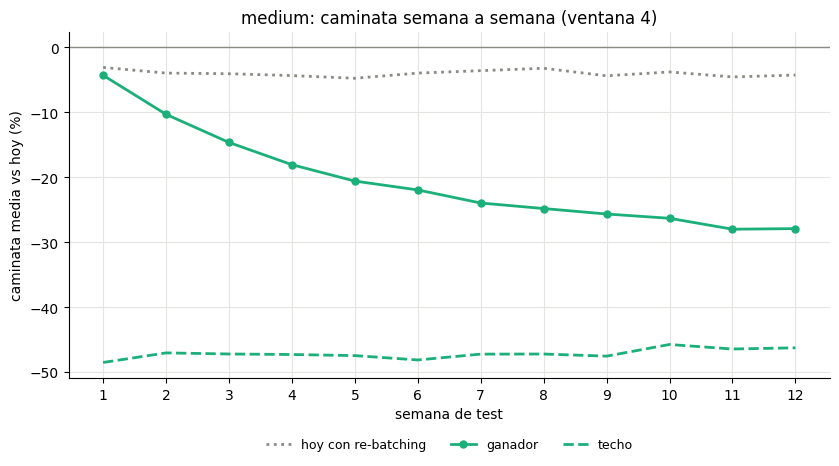

In [19]:
# Diferencia contra hoy por semana.
fig, ax = plt.subplots(figsize=(8.5, 4.8))
x = np.arange(len(semanal))
estilos = {"hoy con re-batching": ("#8a8a85", ":"), "ganador": ("#1baf7a", "-"), "techo": ("#1baf7a", "--")}
for n, (color, ls) in estilos.items():
    ax.plot(x, semanal[n], ls=ls, lw=2, marker="o" if ls == "-" else None, ms=5, color=color, label=n)
ax.axhline(0, color="#8a8a85", lw=1)
ax.set_xticks(x)
ax.set_xticklabels([str(i + 1) for i in x])
ax.grid(True, color="#e5e4e0", lw=0.8)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
ax.set_xlabel("semana de test")
ax.set_ylabel("caminata media vs hoy (%)")
ax.set_title(f"{DATASET}: caminata semana a semana (ventana {VENTANA})")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, fontsize=9)
plt.tight_layout()
plt.show()

**El plan entra rapido al principio y despues se frena.** La demanda en su pasillo del plan pasa del
14,0% en la primera semana al 46,4% en la segunda, al 65,4% en la tercera y al 87,9% en la ultima. La
caminata acompana: -10,3% en la segunda semana, -14,6% en la tercera y -27,9% en la ultima, y en las
ultimas cuatro semanas avanza 2,2 puntos. El techo se mantiene entre -45,7% y -48,5% todo el test, y hoy
con re-batching entre -3,1% y -4,8%.

### 7.3 La ventana

El ganador con cada ventana, y su espera media.

In [20]:
filas_w = {}
for w in VENTANAS:
    filas_w[w] = correr(ctx, plan, regla, w)[0]
ven = pd.DataFrame(filas_w).T.rename_axis("ventana")
ven["promedio vs hoy (%)"] = 100 * (ven["promedio"] / hoy["promedio"] - 1)
ven["final vs hoy (%)"] = 100 * (ven["final"] / hoy["final"] - 1)
ven["espera media (min)"] = [esperas[w] for w in ven.index]
ven[["promedio vs hoy (%)", "final vs hoy (%)", "pasillos por batch", "espera media (min)"]].round(1)

,promedio vs hoy (%),final vs hoy (%),pasillos por batch,espera media (min)
ventana,,,,
1,-0.2,-0.4,7.9,16.6
2,-10.4,-13.8,6.9,48.6
4,-21.5,-27.4,5.8,112.6
8,-28.3,-34.1,5.1,240.5
16,-31.1,-37.1,4.8,496.1


**La ventana fija el intercambio entre caminata y espera.** Con el ganador, el final es -0,4% con FIFO,
-13,8% con ventana 2 (49 minutos de espera media), -27,4% con 4 (113 minutos), -34,1% con 8 (241
minutos) y -37,1% con 16 (496 minutos). La ventana 4 es la referencia; cual conviene la decide la espera
que tolere la operacion.

## 8. Otros depositos

En `small` y `medium-alpha-1.3` se corren hoy, el ganador y el techo. `big` necesita unos 3 GB por
corrida; sus resultados con la misma configuracion se leen del bloque A de la grilla `02_combinatoria`.

In [21]:
del logs, pasos
gc.collect()
filas_o = []
for nombre in OTROS:
    c = preparar(nombre)
    pl = planes_de(c)
    reg = PlanAislePolicy(c.pasillo_de_ubicacion)
    for corrida, args in {"hoy": (pl["vigente"], RandomStoragePolicy(), 1, False),
                          "ganador": (pl[GANADOR], reg, VENTANA, False),
                          "techo": (pl[GANADOR], None, VENTANA, True)}.items():
        filas_o.append({"deposito": nombre, "corrida": corrida, **correr(c, *args)[0]})
    del c
otros = pd.DataFrame(filas_o)
ref = otros.query("corrida == 'hoy'").set_index("deposito")
otros["promedio vs hoy (%)"] = 100 * (otros["promedio"] / otros["deposito"].map(ref["promedio"]) - 1)
otros["final vs hoy (%)"] = 100 * (otros["final"] / otros["deposito"].map(ref["final"]) - 1)
otros.set_index(["deposito", "corrida"])[["promedio vs hoy (%)", "final vs hoy (%)", "mudanzas por reposicion"]].round(1)

promedio vs hoy (%)  final vs hoy (%)  mudanzas por reposicion
deposito         corrida                                                                
small            hoy                      0.0               0.0                     1357
                 ganador                 -0.1              -0.2                      441
                 techo                  -27.8             -28.3                        0
medium-alpha-1.3 hoy                      0.0               0.0                    13437
                 ganador                -23.3             -28.9                     3003
                 techo                  -48.1             -48.1                        0

In [22]:
# big, leido de la grilla 02_combinatoria.
g = load_results(GRILLA).query("block == 'A' and routing == 's_shape'")
espera_w4 = g.query("start == 'real' and window == @VENTANA").groupby("dataset")["wait_mean_min"].first().round(0)
print("espera media de una orden con ventana 4 (minutos):", espera_w4.to_dict())
g = g[g["dataset"] == "big"]
hoy_big = g.query("slot_method == 'vigente' and replenishment == 'random' and window == 1").iloc[0]
big = pd.DataFrame({
    "hoy": hoy_big,
    "ganador": g.query("slot_method == @GANADOR and start == 'real' and window == @VENTANA").iloc[0],
    "techo": g.query("slot_method == @GANADOR and start == 'plan' and window == @VENTANA").iloc[0]}).T
big["promedio vs hoy (%)"] = 100 * (big["mean_distance"].astype(float) / float(hoy_big["mean_distance"]) - 1)
big["final vs hoy (%)"] = 100 * (big["last14_distance"].astype(float) / float(hoy_big["last14_distance"]) - 1)
big[["promedio vs hoy (%)", "final vs hoy (%)", "relocations"]].astype(float).round(1)

espera media de una orden con ventana 4 (minutos): {'big': 51.0, 'medium': 113.0, 'medium-alpha-1.3': 113.0, 'small': 843.0}


,promedio vs hoy (%),final vs hoy (%),relocations
hoy,0.0,0.0,29860.0
ganador,-30.8,-36.5,9324.0
techo,-59.9,-59.8,0.0


**En `medium-alpha-1.3` se repite el patron:** el ganador gana 28,9% al final y 23,3% en promedio,
contra 48,1% del techo.

**En `big` tambien:** 36,5% al final y 30,8% en promedio, contra 59,8% del techo, con 9.324 mudanzas
contra 29.860 de hoy. Como `big` recibe mas ordenes por hora, con ventana 4 una orden espera 51 minutos
de media.

**En `small` nada gana** (0,2% al final), aunque el techo es 28,3%: con 4 pasillos, mientras quede
demanda fuera de su pasillo casi cualquier batch entra a los 4. Ademas `small` recibe pocas ordenes, y
con ventana 4 una orden espera 843 minutos de media, unas 14 horas.

## 9. Por que esta configuracion: lo que dijo la grilla

La grilla `02_combinatoria` barre cada factor con el mismo regimen. Aca se leen sus resultados para
`medium` (final contra hoy, los ultimos 14 dias) y se muestra, factor por factor, por que se eligio
cada valor del ganador.

In [23]:
r = load_results(GRILLA)
r = r[r["dataset"] == DATASET].copy()
h = r.query("slot_method == 'vigente' and replenishment == 'random' and window == 1 and routing == 's_shape'").iloc[0]
r["final vs hoy (%)"] = 100 * (r["last14_distance"] / h["last14_distance"] - 1)
r["promedio vs hoy (%)"] = 100 * (r["mean_distance"] / h["mean_distance"] - 1)
r["plan"] = np.where(r["slot_method"] == "bilevel", "bilevel " + r["slot_clustering"].astype(str) + "/" + r["slot_zone_cost"].astype(str), r["slot_method"])
print("Slotting (bloque A): final vs hoy con la regla base, por ventana")
r.query("block == 'A' and start == 'real' and replenishment == 'plan_aisle'").pivot_table(
    index="plan", columns="window", values="final vs hoy (%)").sort_values(4).round(1)

Slotting (bloque A): final vs hoy con la regla base, por ventana


window,1,2,4,8,16
plan,,,,,
merchant_aisle_fill,-0.4,-13.8,-27.4,-34.1,-37.1
bilevel merchant/aisle_order,-0.3,-13.2,-26.6,-33.2,-36.8
swap_search,-0.3,-12.5,-21.7,-27.1,-30.4
bilevel demand_class/dock,-0.6,-11.0,-17.4,-22.5,-24.8
bilevel demand_class/aisle_order,-0.9,-11.3,-17.3,-20.5,-21.8
bilevel merchant/dock,-0.0,-8.7,-17.3,-24.2,-28.7
demand_greedy,-0.6,-11.1,-17.1,-21.7,-24.0
linear_assignment,-0.7,-11.0,-16.8,-21.2,-24.4
aisle_fill,-1.0,-10.5,-16.8,-19.9,-22.6


In [24]:
print("Regla de reposicion (bloque R): final vs hoy, ventana 4")
R = r.query("block == 'R' and window == 4").copy()
R["regla"] = np.where(R["replenishment"] == "plan_aisle", "plan_aisle " + R["rule_trigger"] + "/" + R["rule_target"],
                      R["replenishment"] + " lambda=" + R["replenishment_lam"].astype(str))
R.pivot_table(index="regla", columns="plan", values="final vs hoy (%)").round(1)

Regla de reposicion (bloque R): final vs hoy, ventana 4


plan,aisle_fill,demand_greedy,merchant_aisle_fill,vigente
regla,,,,
objective_greedy lambda=0.0,NaN,NaN,NaN,-20.2
objective_greedy lambda=0.5,NaN,NaN,NaN,-15.6
objective_greedy lambda=1.0,NaN,NaN,NaN,-11.7
plan_aisle always/aisle,-12.4,-14.1,-27.1,-11.0
plan_aisle always/location,-2.5,-2.2,-3.5,-11.0
plan_aisle stockout/aisle,-16.8,-17.1,-27.4,-11.0
plan_aisle stockout/location,-12.5,-11.1,-27.1,-11.0
random lambda=0.5,NaN,NaN,NaN,-4.2


In [25]:
print("Frecuencia (bloque F) y algoritmo de batching (bloque B): final vs hoy, ventana 4")
pd.concat({"frecuencia": r.query("block == 'F' and window == 4").pivot_table(index="plan", columns="demand_metric", values="final vs hoy (%)"),
           "pasadas del re-batching": r.query("block == 'B' and window == 4").pivot_table(index="plan", columns="batching_passes", values="final vs hoy (%)")},
          axis=1).round(1)

Frecuencia (bloque F) y algoritmo de batching (bloque B): final vs hoy, ventana 4


frecuencia                                          pasadas del re-batching      
                    pick_lines total_units unique_batches unique_orders                       0    20
plan                                                                                                 
aisle_fill               -16.8       -16.5          -16.5         -16.8                     NaN   NaN
demand_greedy            -17.1       -16.8          -16.6         -17.1                   -15.9 -17.1
merchant_aisle_fill      -27.4       -27.6          -27.7         -27.4                   -26.7 -27.4

**Slotting.** Con la regla y ventana 4, el plan por merchant es el mejor (-27,4% al final), seguido de
`bilevel merchant/aisle_order` (-26,6%), que es la misma idea, agrupar por merchant y armar las zonas
pasillo por pasillo, con un problema de transporte. Los planes por demanda y los otros tres binivel
quedan entre -16,8% y -17,4%, y `swap_search` en -21,7%. Los dos primeros puestos se repiten en todas
las ventanas desde 2; con FIFO ningun plan gana mas de 1%.

**Regla.** La base, mover solo al agotarse y al pasillo, es la mejor o empata con los cuatro planes; mover en cada
reposicion o apuntar a la ubicacion exacta empata o empeora, y las dos cosas juntas casi borran la
ganancia (-3,5% con el plan por merchant). Sin plan, `objective_greedy` con $\lambda = 0$, que reubica
solo por afinidad, gana 20,2%: la afinidad de los datos, que es el merchant, sirve aun sin plan, pero
menos que con el plan por merchant y la regla.

**Frecuencia y batching.** Las cuatro definiciones de $f$ dan resultados a medio punto o menos entre
si, asi que se queda `pick_lines`. Intercambiar ordenes despues de construir los batches suma 0,7 puntos
con el plan por merchant, y se mantiene. Los parametros del QAP (`swap_search`) estan en el bloque Q de
`02_combinatoria`.

## 10. Lectura

Todas las cifras son la caminata media por batch en S contra hoy (el deposito real, reposiciones como
en los datos, batches FIFO), partiendo del deposito real al corte.

**El ganador** combina el slotting por merchant (`merchant_aisle_fill`), la regla de reposicion
`plan_aisle` (al agotarse, a un hueco del pasillo del plan) y re-batching con ventana 4. En `medium` gana
27,4% en los ultimos 14 dias y 21,5% en promedio sobre los 72 dias de test (7.1).

**Hacen falta las dos piezas.** Sin re-armar los batches el plan gana 0,4%; sin plan, re-armar los
batches gana 4,2% (7.1).

**Llega a algo mas de la mitad del techo.** El plan entra solo por las mudanzas al reponer: al final
del test el 87,9% de la demanda esta en su pasillo del plan, y lo que falta son SKUs que casi no se
agotan. Con el plan aplicado de una vez se ganaria 46,3% (7.1 y 7.2).

**No agrega mudanzas:** 3.362 en el test contra 13.608 de hoy (7.1).

**La afinidad que aprovecha es la del merchant,** la unica que tienen los datos (2): el plan pone cada
orden en un pasillo (4) y el re-batching junta las ordenes de los mismos pasillos.

**Se repite en `medium-alpha-1.3` y en `big`** (28,9% y 36,5% al final); en `small` no gana nada (8).

**El costo es la espera:** 113 minutos de media con ventana 4 en `medium`, contra 17 con FIFO. La
ventana fija el intercambio entre caminata y espera, de -13,8% con 49 minutos a -37,1% con 496 (7.3).

**Lo que falta:** cuanta espera tolera la operacion real, la hora real de llegada de las ordenes y la
congestion, que el simulador no modela.